In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

# Business Analysis

## Project Overview
This notebook focuses on analysing the Olist e-commerce business to identify revenue trends, customer purchasing behaviour, product performance, payment patterns, delivery performance, and customer satisfaction.

## Objectives
- Analyse overall business revenue and sales performance.
- Identify top-performing products and categories.
- Understand customer purchasing behaviour.
- Examine payment methods and order patterns.
- Evaluate delivery performance.
- Analyse customer reviews and satisfaction.
- Provide actionable business recommendations.

In [2]:
sales = pd.read_csv("../data/processed/sales_analysis.csv")
customers = pd.read_csv("../data/processed/customer_analysis.csv")
payments = pd.read_csv("../data/processed/payment_analysis.csv")
reviews = pd.read_csv("../data/processed/review_analysis.csv")
sellers = pd.read_csv("../data/processed/seller_analysis.csv")
deliveries = pd.read_csv("../data/processed/delivery_analysis.csv")
products = pd.read_csv("../data/processed/product_analysis.csv")

In [3]:
datasets = {
    "Sales": sales,
    "Customers": customers,
    "Payments": payments,
    "Reviews": reviews,
    "Sellers": sellers,
    "Deliveries": deliveries,
    "Products": products
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Sales: (112650, 12)
Customers: (99441, 8)
Payments: (103887, 8)
Reviews: (99992, 5)
Sellers: (112650, 11)
Deliveries: (113425, 28)
Products: (112650, 14)


In [4]:
sales.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english,customer_id,order_status,order_purchase_timestamp,customer_unique_id
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,871766c5855e863f6eccc05f988b23cb
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,eb28e67c4c0b83846050ddfb8a35d051
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,furniture_decor,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,3818d81c6709e39d06b2738a8d3a2474
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumery,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,af861d436cfc08b2c2ddefd0ba074622
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,garden_tools,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,64b576fb70d441e8f1b2d7d446e483c5
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,housewares,816cbea969fe5b689b39cfc97a506742,delivered,2017-05-15 21:42:34,85c835d128beae5b4ce8602c491bf385
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,telephony,32e2e6ab09e778d99bf2e0ecd4898718,delivered,2017-12-10 11:53:48,635d9ac1680f03288e72ada3a1035803
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,garden_tools,9ed5e522dd9dd85b4af4a077526d8117,delivered,2018-07-04 12:08:27,fda4476abb6307ab3c415b7e6d026526
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,health_beauty,16150771dfd4776261284213b89c304e,delivered,2018-03-19 18:40:33,639d23421f5517f69d0c3d6e6564cf0e
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,books_technical,351d3cb2cee3c7fd0af6616c82df21d3,delivered,2018-07-02 13:59:39,0782c41380992a5a533489063df0eef6


In [5]:
print("total_revenue:",sales.price.sum())
print("total_orders:",sales["order_id"].nunique())
print("total_items_sold:", sales.shape[0])
print("average_order_value:",sales.price.sum()/sales.order_id.nunique())
print("average_item_price:", sales["price"].mean())

total_revenue: 13591643.7
total_orders: 98666
total_items_sold: 112650
average_order_value: 137.75407637889444
average_item_price: 120.65373901464713


In [6]:
sales["order_purchase_timestamp"]=pd.to_datetime(sales["order_purchase_timestamp"])

In [7]:
monthly_sales=sales.groupby(sales["order_purchase_timestamp"].dt.to_period('M')).agg(total_revenue=("price","sum"),total_orders=("order_id","nunique"),total_items_sold=("order_id","count"))

In [8]:
monthly_sales

,total_revenue,total_orders,total_items_sold
order_purchase_timestamp,,,
2016-09,267.36,3,6
2016-10,49507.66,308,363
2016-12,10.90,1,1
2017-01,120312.87,789,955
2017-02,247303.02,1733,1951
2017-03,374344.30,2641,3000
2017-04,359927.23,2391,2684
2017-05,506071.14,3660,4136
2017-06,433038.60,3217,3583


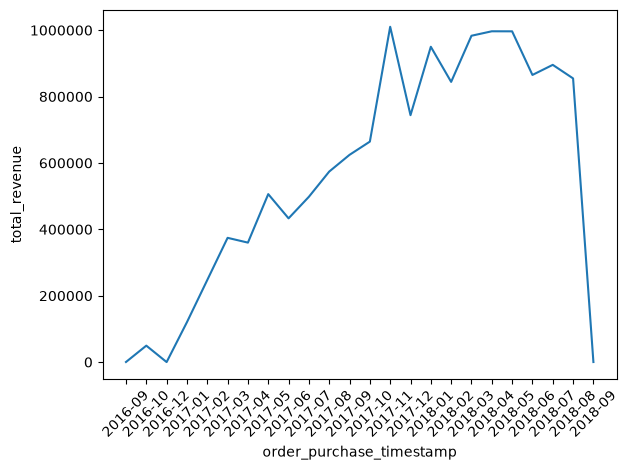

In [9]:
sns.lineplot(data=monthly_sales,x=monthly_sales.index.astype(str),y="total_revenue")
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain',axis='y')
plt.tight_layout()
plt.show()

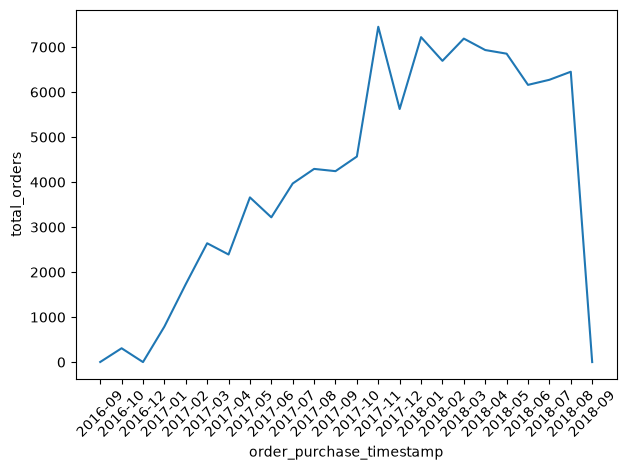

In [10]:
sns.lineplot(data=monthly_sales,x=monthly_sales.index.astype(str),y="total_orders")
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain',axis='y')
plt.tight_layout()
plt.show()

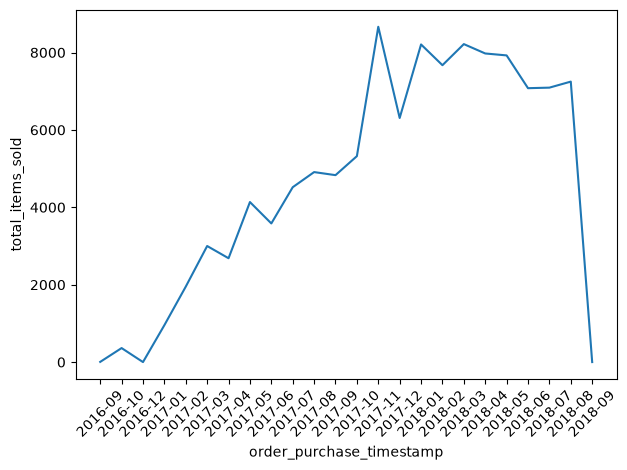

In [11]:
sns.lineplot(data=monthly_sales,x=monthly_sales.index.astype(str),y="total_items_sold")
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain',axis='y')
plt.tight_layout()
plt.show()

In [12]:
monthly_sales["average_order_value"]=(monthly_sales["total_revenue"]/monthly_sales["total_orders"])
monthly_sales["average_order_value"].sort_values()

order_purchase_timestamp
2016-12     10.900000
2016-09     89.120000
2017-07    125.480343
2018-02    126.109756
2018-01    131.583152
2017-12    132.274924
2018-08    132.468433
2017-08    133.699436
2017-06    134.609450
2017-11    135.588695
2018-03    136.785398
2017-05    138.270803
2018-06    140.442258
2017-03    141.743393
2017-02    142.702262
2018-07    142.755814
2018-04    143.733451
2018-09    145.000000
2017-10    145.407056
2018-05    145.413349
2017-09    147.160427
2017-04    150.534182
2017-01    152.487795
2016-10    160.739156
Freq: M, Name: average_order_value, dtype: float64

In [13]:
product_category_sales=sales.groupby("product_category_name_english").agg(total_revenue=("price","sum"),total_orders=("price","nunique"),total_items_sold=("order_id","count"))
product_category_sales

,total_revenue,total_orders,total_items_sold
product_category_name_english,,,
agro_industry_and_commerce,72530.47,90,212
air_conditioning,55024.96,115,297
art,24202.64,68,209
arts_and_craftmanship,1814.01,19,24
audio,50688.50,80,364
...,...,...,...
stationery,230943.23,389,2517
tablets_printing_image,7528.41,16,83
telephony,323667.53,444,4545


In [14]:
product_category_sales["average_order_value"]=(product_category_sales["total_revenue"]/product_category_sales["total_orders"])
product_category_sales["average_order_value"].sort_values(ascending=False).head(10)

product_category_name_english
computers                                6370.375143
watches_gifts                            1396.298586
office_furniture                         1356.241089
small_appliances_home_oven_and_coffee    1248.571316
cool_stuff                               1191.915291
bed_bath_table                           1190.572537
health_beauty                             996.580633
home_appliances_2                         985.371652
home_confort                              976.200667
furniture_decor                           926.094530
Name: average_order_value, dtype: float64

In [15]:
delivered_sales = sales[sales["order_status"] == "delivered"]
delivered_sales

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english,customer_id,order_status,order_purchase_timestamp,customer_unique_id
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,871766c5855e863f6eccc05f988b23cb
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,eb28e67c4c0b83846050ddfb8a35d051
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,furniture_decor,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,3818d81c6709e39d06b2738a8d3a2474
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumery,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,af861d436cfc08b2c2ddefd0ba074622
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,garden_tools,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,64b576fb70d441e8f1b2d7d446e483c5
...,...,...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,housewares,b51593916b4b8e0d6f66f2ae24f2673d,delivered,2018-04-23 13:57:06,0c9aeda10a71f369396d0c04dce13a64
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,computers_accessories,84c5d4fbaf120aae381fad077416eaa0,delivered,2018-07-14 10:26:46,0da9fe112eae0c74d3ba1fe16de0988b
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,sports_leisure,29309aa813182aaddc9b259e31b870e6,delivered,2017-10-23 17:07:56,cd79b407828f02fdbba457111c38e4c4
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,computers_accessories,b5e6afd5a41800fdf401e0272ca74655,delivered,2017-08-14 23:02:59,eb803377c9315b564bdedad672039306


In [16]:
monthly_sales_delivered=delivered_sales.groupby(delivered_sales["order_purchase_timestamp"].dt.to_period('M')).agg(total_revenue=("price","sum"),total_orders=("order_id","nunique"),total_items_sold=("order_id","count"))

In [17]:
monthly_sales_delivered

,total_revenue,total_orders,total_items_sold
order_purchase_timestamp,,,
2016-09,134.97,1,3
2016-10,40325.11,265,313
2016-12,10.90,1,1
2017-01,111798.36,750,913
2017-02,234223.40,1653,1858
2017-03,359198.85,2546,2897
2017-04,340669.68,2303,2569
2017-05,489338.25,3546,4004
2017-06,421923.37,3135,3489


In [18]:
product_category_sales_delivered=delivered_sales.groupby("product_category_name_english").agg(total_revenue=("price","sum"),total_orders=("price","nunique"),total_items_sold=("order_id","count"))
product_category_sales_delivered.sort_values(by="total_revenue",ascending=False).head(10)

,total_revenue,total_orders,total_items_sold
product_category_name_english,,,
health_beauty,1233131.72,1249,9465
watches_gifts,1166176.98,846,5859
bed_bath_table,1023434.76,866,10953
sports_leisure,954852.55,1124,8431
computers_accessories,888724.61,978,7644
furniture_decor,711927.69,774,8160
housewares,615628.69,1087,6795
cool_stuff,610204.10,524,3718
auto,578966.65,848,4140


In [19]:
product_category_sales_delivered["average_revenue_per_order"]=(product_category_sales_delivered["total_revenue"]/product_category_sales_delivered["total_orders"])
product_category_sales_delivered["average_revenue_per_order"].sort_values(ascending=False).head(10)

product_category_name_english
computers                                6248.118286
watches_gifts                            1378.459787
office_furniture                         1340.771550
small_appliances_home_oven_and_coffee    1259.177297
bed_bath_table                           1181.795335
cool_stuff                               1164.511641
health_beauty                             987.295212
home_confort                              983.194068
home_appliances_2                         955.344690
furniture_decor                           919.803217
Name: average_revenue_per_order, dtype: float64

In [20]:
customers.head(10)

,order_id,customer_id,order_status,order_purchase_timestamp,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,80bb27c7c16e8f973207a5086ab329e2,86320,congonhinhas,PR
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,36edbb3fb164b1f16485364b6fb04c73,98900,santa rosa,RS
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,932afa1e708222e5821dac9cd5db4cae,26525,nilopolis,RJ
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,39382392765b6dc74812866ee5ee92a7,99655,faxinalzinho,RS
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,299905e3934e9e181bfb2e164dd4b4f8,18075,sorocaba,SP


In [21]:
print(customers["customer_unique_id"].nunique())
print(customers["order_id"].nunique())

96096
99441


In [22]:
print(customers["customer_unique_id"].duplicated().sum())

3345


In [23]:
customer_orders = customers.groupby("customer_unique_id")["order_id"].count().sort_values(ascending=False)

(customer_orders>1).sum()


np.int64(2997)

In [24]:
delivered_customers=customers[customers["order_status"]=="delivered"]

In [25]:
print(delivered_customers["customer_unique_id"].nunique())
print(delivered_customers["order_id"].nunique())
print(delivered_customers["customer_unique_id"].duplicated().sum())

93358
96478
3120


In [26]:
delivered_customer_orders = delivered_customers.groupby("customer_unique_id")["order_id"].count().sort_values(ascending=False)

(delivered_customer_orders>1).sum()


np.int64(2801)

In [27]:
delivered_sales.groupby("customer_unique_id")["price"].sum().sort_values(ascending=False).head(10)

customer_unique_id
0a0a92112bd4c708ca5fde585afaa872    13440.0
da122df9eeddfedc1dc1f5349a1a690c     7388.0
763c8b1c9c68a0229c42c9fc6f662b93     7160.0
dc4802a71eae9be1dd28f5d788ceb526     6735.0
459bef486812aa25204be022145caa62     6729.0
ff4159b92c40ebe40454e3e6a7c35ed6     6499.0
4007669dec559734d6f53e029e360987     5934.6
eebb5dda148d3893cdaf5b5ca3040ccb     4690.0
48e1ac109decbb87765a3eade6854098     4590.0
a229eba70ec1c2abef51f04987deb7a5     4400.0
Name: price, dtype: float64

In [28]:
delivered_customer_orders[delivered_customer_orders>1]

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    15
3e43e6105506432c953e165fb2acf44c     9
6469f99c1f9dfae7733b25662e7f1782     7
1b6c7548a2a1f9037c1fd3ddfed95f33     7
ca77025e7201e3b30c44b472ff346268     7
                                    ..
ff03923ad1eb9e32304deb7f9b2a45c9     2
ff44401d0d8f5b9c54a47374eb48c1b8     2
ff8892f7c26aa0446da53d01b18df463     2
323f8f14acb90e50f86f1885b6b53c6d     2
ffe254cc039740e17dd15a5305035928     2
Name: order_id, Length: 2801, dtype: int64

In [29]:
repeat_customer_ids = delivered_customer_orders[
    delivered_customer_orders > 1
].index

In [30]:
repeat_customer_sale=delivered_sales[delivered_sales["customer_unique_id"].isin(repeat_customer_ids)]

In [31]:
repeat_customer_sale

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english,customer_id,order_status,order_purchase_timestamp,customer_unique_id
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,eb28e67c4c0b83846050ddfb8a35d051
39,0017afd5076e074a48f1f1a4c7bac9c5,1,fe59a1e006df3ac42bf0ceb876d70969,25c5c91f63607446a97b143d2d535d31,2017-04-24 22:25:19,809.10,44.29,computers_accessories,8085a9af46f619bc25966f151a362b0d,delivered,2017-04-06 22:16:10,98758d88bf4b8eef1372ddee45d63178
55,0020a222f55eb79a372d0efee3cca688,1,e19ddcc85537b41f22116c8d5425ef46,8a32e327fe2c1b3511609d81aaf9f042,2017-08-21 03:03:44,29.99,15.10,furniture_decor,0c45155afd8ff99622c40824057f9b34,delivered,2017-08-15 02:45:18,87ae4c644c15d9c6b6f826dfec33b340
95,0035246a40f520710769010f752e7507,1,8a6187b2665118d5095f99a25fd7ba7a,4a3ca9315b744ce9f8e9374361493884,2017-08-23 01:25:39,87.00,12.11,bed_bath_table,4bcf2ad7ccc061c13ff360aae5b7abcd,delivered,2017-08-17 00:57:23,d56ded4569dd9821b2f83710a56afbde
104,003a7f59d7e08a9c61d9e2881fe6459c,1,a4d286543a67e29c930c99cbd7a55a8f,b410bdd36d5db7a65dcd42b7ead933b8,2018-08-22 11:49:46,119.00,15.28,housewares,f7838e5eeb3271df42376952e651e403,delivered,2018-08-19 12:51:50,3725c5b8c1cf5ee69158f66922a862c4
...,...,...,...,...,...,...,...,...,...,...,...,...
112508,ffabaa69e709f1ec58faf2f706c8c8ee,1,e59dd207c69d86e890febadc796d1078,1c68394e931a64f90ea236c5ea590300,2018-03-05 22:35:27,144.41,17.45,cool_stuff,1ab2ae086ad3c25f52354abd033639e1,delivered,2018-02-21 22:21:26,acc4424c209233de519e034152f30304
112524,ffb47bf24e3f64dc0a2059a9181b976a,1,8ee15ce472d128e8ea95d9a24c2d397c,6edacfd9f9074789dad6d62ba7950b9c,2017-06-07 11:03:17,46.90,9.34,housewares,069dca5337f1cf3f778d0cfa43ce8dd9,delivered,2017-06-01 10:48:48,c130bf40aa6d3bdb444b04a8d78adf5a
112601,ffe49171e120186dcc4c444b55691810,1,102cdda7fcf3cb71b5f9d6d2a3e56b58,8931a84a914b3fe9b1ddaa4d704947ca,2017-04-04 02:15:36,68.00,8.85,perfumery,9be83b1a15980ed71eadb4dff917fa29,delivered,2017-03-29 02:00:08,71d2dbb6d2f52d568ca9d69c815a4331
112619,ffee31fb4b5e35c9123608015637c495,1,b10ecf8e33aaaea419a9fa860ea80fb5,0241d4d5d36f10f80c644447315af0bd,2018-08-21 10:10:11,99.00,13.52,furniture_decor,11e0f43ab4e2d2c48348dd9332c0ef80,delivered,2018-08-18 10:00:59,4e15fee963523774998876e3624952f4


In [32]:
repeat_customer_ids.shape

(2801,)

In [33]:
repeat_customer_sale.groupby("customer_unique_id")["price"].sum().sort_values(ascending=False).head(10)

customer_unique_id
da122df9eeddfedc1dc1f5349a1a690c    7388.00
c8460e4251689ba205045f3ea17884a1    4080.00
59d66d72939bc9497e19d89c61a96d5f    3459.00
d77aa95864ae5b42160937615628723a    2400.00
7b0eaf68a16e4808e5388c67345033c9    2238.42
86df00dc5fd68f4dd5d5945ca19f3ed6    2200.00
6ddbc64bd04d40f7768ff088d94cbeb8    2108.00
73601b1eec55943e90ce8d61253d5c09    2009.98
1da09dd64e235e7c2f29a4faff33535c    1980.28
906a8a4ec9f3d4c3e64fa6d1c4fe6009    1835.00
Name: price, dtype: float64

In [34]:
repeat_customer_revenue = repeat_customer_sale["price"].sum()

total_revenue = delivered_sales["price"].sum()

repeat_customer_revenue / total_revenue * 100

np.float64(5.509275453808615)

In [35]:
payments

,order_id,customer_id,order_status,order_purchase_timestamp,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,1.0,credit_card,1.0,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,3.0,voucher,1.0,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2.0,voucher,1.0,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,1.0,boleto,1.0,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,1.0,credit_card,3.0,179.12
...,...,...,...,...,...,...,...,...
103882,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,1.0,credit_card,3.0,85.08
103883,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,1.0,credit_card,3.0,195.00
103884,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,1.0,credit_card,5.0,271.01
103885,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,1.0,credit_card,4.0,441.16


In [36]:
payments.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'payment_sequential', 'payment_type', 'payment_installments',
       'payment_value'],
      dtype='str')

In [37]:
delivered_payments=payments[payments["order_status"]=="delivered"]

In [38]:
delivered_payments.shape

(100757, 8)

In [39]:
delivered_payments["payment_type"].value_counts()

payment_type
credit_card    74586
boleto         19191
voucher         5493
debit_card      1486
Name: count, dtype: int64

In [42]:
delivered_payments.groupby("payment_type")["payment_value"].sum().sort_values(ascending=False)

payment_type
credit_card    12101094.88
boleto          2769932.58
voucher          343013.19
debit_card       208421.12
Name: payment_value, dtype: float64

In [44]:
delivered_payments["payment_installments"].value_counts()

payment_installments
1.0     50929
2.0     12075
3.0     10164
4.0      6891
10.0     5150
5.0      5095
8.0      4136
6.0      3804
7.0      1563
9.0       618
12.0      128
15.0       72
18.0       27
11.0       22
24.0       18
20.0       16
13.0       15
14.0       14
17.0        7
16.0        5
21.0        3
0.0         2
23.0        1
22.0        1
Name: count, dtype: int64

In [49]:
payments_type_sale=delivered_payments.groupby("payment_type").agg(payment_value=("payment_value","sum"),payment_count=("payment_type","count"))

In [50]:
payments_type_sale["average_payment_value"]=payments_type_sale["payment_value"]/payments_type_sale["payment_count"]

In [53]:
payments_type_sale.sort_values(by="payment_value",ascending=False)

,payment_value,payment_count,average_payment_value
payment_type,,,
credit_card,12101094.88,74586,162.243516
boleto,2769932.58,19191,144.334979
voucher,343013.19,5493,62.445511
debit_card,208421.12,1486,140.256474


In [54]:
deliveries

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,invalid_delivery_date,canceled_with_delivery_date,...,seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,actual_delivery_days,delivery_delay_days,purchase_to_approval_hours,approval_to_carrier_hours,carrier_to_customer_hours
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,...,SP,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,8.0,-8.0,0.178333,56.795833,145.503611
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,...,SP,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,13.0,-6.0,30.713889,11.109167,288.945833
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,...,SP,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,9.0,-18.0,0.276111,4.910278,220.274722
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,...,MG,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,13.0,-13.0,0.298056,89.900000,226.811944
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,...,SP,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,2.0,-10.0,1.030556,21.434722,46.507778
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113420,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,False,False,...,SP,da62f9e57a76d978d02ab5362c509660,11722,praia grande,SP,22.0,-2.0,0.194167,34.201389,498.253889
113421,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,False,False,...,SP,737520a9aad80b3fbbdad19b66b37b30,45920,nova vicosa,BA,24.0,-6.0,0.292500,29.802778,566.530833
113422,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,False,False,...,MG,5097a5312c8b157bb7be58ae360ef43c,28685,japuiba,RJ,17.0,-21.0,0.131667,89.978333,319.964167
113423,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,False,False,...,MG,5097a5312c8b157bb7be58ae360ef43c,28685,japuiba,RJ,17.0,-21.0,0.131667,89.978333,319.964167


In [55]:
deliveries.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'invalid_delivery_date', 'canceled_with_delivery_date',
       'delivered_without_approval', 'invalid_approval_carrier_sequence',
       'invalid_carrier_customer_sequence', 'order_item_id', 'seller_id',
       'shipping_limit_date', 'seller_zip_code_prefix', 'seller_city',
       'seller_state', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state', 'actual_delivery_days',
       'delivery_delay_days', 'purchase_to_approval_hours',
       'approval_to_carrier_hours', 'carrier_to_customer_hours'],
      dtype='str')

In [56]:
delivered_deliveries=deliveries[deliveries["order_status"]=="delivered"]

In [58]:
delivered_deliveries.shape

(110197, 28)

In [59]:
delivered_deliveries["actual_delivery_days"].describe()

count    110189.000000
mean         12.007342
std           9.451153
min           0.000000
25%           6.000000
50%          10.000000
75%          15.000000
max         209.000000
Name: actual_delivery_days, dtype: float64

In [66]:
on_time_deliveries=delivered_deliveries[delivered_deliveries["delivery_delay_days"]<=0]
late_deliveries=delivered_deliveries[delivered_deliveries["delivery_delay_days"]>0]

In [67]:
on_time_order=on_time_deliveries["order_id"].nunique()
late_orders=late_deliveries["order_id"].nunique()

In [69]:
print("On-time/Early orders:", on_time_order)
print("Late orders:", late_orders)

On-time/Early orders: 89936
Late orders: 6534


In [70]:
late_deliveries["delivery_delay_days"].describe()

count    7264.000000
mean       10.488574
std        14.500566
min         1.000000
25%         3.000000
50%         7.000000
75%        13.000000
max       188.000000
Name: delivery_delay_days, dtype: float64

In [76]:
delivered_deliveries.drop_duplicates(subset="order_id").groupby("customer_state")["actual_delivery_days"].mean()

customer_state
AC    20.637500
AL    24.040302
AM    25.986207
AP    26.731343
BA    18.866400
CE    20.817826
DF    12.509135
ES    15.331830
GO    15.150741
MA    21.117155
MG    11.542188
MS    15.191155
MT    17.593679
PA    23.316068
PB    19.953578
PE    17.965474
PI    18.993697
PR    11.526711
RJ    14.848583
RN    18.824895
RO    18.913580
RR    28.975610
RS    14.819237
SC    14.475183
SE    21.029851
SP     8.298094
TO    17.226277
Name: actual_delivery_days, dtype: float64

In [77]:
reviews.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'review_score'],
      dtype='str')

In [78]:
delivered_reviews=reviews[reviews["order_status"]=="delivered"]

In [79]:
delivered_reviews.shape

(97007, 5)

In [81]:
delivered_reviews["review_score"].value_counts()

review_score
5.0    57066
4.0    18987
1.0     9406
3.0     7961
2.0     2941
Name: count, dtype: int64

In [83]:
delivered_reviews["review_score"].describe()

count    96361.000000
mean         4.155717
std          1.284986
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64

In [87]:
conditions = [
    delivered_reviews["review_score"] >= 4,
    delivered_reviews["review_score"] == 3,
    delivered_reviews["review_score"] <= 2
]

categories = ["Positive", "Neutral", "Negative"]

delivered_reviews["review_category"] = np.select(conditions, categories,default="unknown")

delivered_reviews["review_category"].value_counts()

review_category
Positive    76053
Negative    12347
Neutral      7961
unknown       646
Name: count, dtype: int64